# 02 - Features and Time-to-Failure Dataset
**Project:** Predictive Maintenance of IoT Sensors (Intel Berkeley Research Lab)
**CRISP-DM phase:** 3 - Data Preparation

## 0. Setup

In [ ]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
try:                                    # Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/sensor-failure-prediction")
except ImportError:
    PROJECT = Path("..").resolve()

PROC_DIR = PROJECT / "data/processed"
FIG_DIR  = PROJECT / "reports/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

GRID_MIN   = 10                        # grid resolution in minutes
GRID       = f"{GRID_MIN}min"
WINDOWS_H  = [1, 6, 24, 48]            # feature windows in hours
BINS_PER_H = 60 // GRID_MIN
SEED = 42
HORIZONS_PREVIEW = [6, 12, 24, 48, 72]

meta = json.load(open(PROC_DIR / "failure_definition.json"))
V_LOW = meta["v_low"]
MED_DT = pd.Timedelta(seconds=meta["median_interval_s"])
EXPECTED_PER_BIN = GRID_MIN * 60 / MED_DT.total_seconds()      # readings per bin when the node is healthy

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"grid {GRID} | windows {WINDOWS_H} h | V_LOW {V_LOW} | about {EXPECTED_PER_BIN:.1f} readings per bin")

Mounted at /content/drive
grid 10min | windows [1, 6, 24, 48] h | V_LOW 2.4 | about 18.0 readings per bin


## 1. Load and cut each node at its failure

In [ ]:
df = pd.read_parquet(PROC_DIR / "intel_clean.parquet")
mote = pd.read_csv(PROC_DIR / "mote_status.csv", index_col="moteid",
                   parse_dates=["first_ts", "last_ts", "t_garbage", "t_lowv", "t_silent", "t_fail"])

# The garbage flag fires at the END of a 60-reading window, so the real onset is earlier
is_garbage = mote.fail_type == "garbage"
mote["t_onset"] = mote.t_fail
mote.loc[is_garbage, "t_onset"] = mote.t_fail[is_garbage] - meta["bad_window"] * MED_DT

n0 = len(df)
df = df.merge(mote[["t_onset"]], left_on="moteid", right_index=True, how="left")
df = df[df.t_onset.isna() | (df.timestamp < df.t_onset)].drop(columns="t_onset").reset_index(drop=True)
print(f"rows: {n0:,} -> {len(df):,} after removing everything from the failure onset on ({(1 - len(df)/n0)*100:.1f} % removed)")
mote[["fail_type", "t_onset"]].head()

rows: 2,303,290 -> 1,880,986 after removing everything from the failure onset on (18.3 % removed)


,fail_type,t_onset
moteid,,
1,garbage,2004-03-23 05:52:15.404053060
2,garbage,2004-03-23 06:20:57.543579060
3,garbage,2004-03-24 16:09:18.714963060
4,garbage,2004-03-21 07:01:43.389273060
5,silent,2004-03-03 17:10:56.993959000


## 2. Regular 10-minute grid (causal)
`closed="right", label="right"`: the bin stamped *t* only uses readings in (t - 10 min, t]. Empty bins stay empty (no invented data).
We also keep the **reporting rate** (readings per bin / expected) and the share of readings with a missing voltage (about 4 % of rows have none).

In [ ]:
def to_grid(d):
    r = d.set_index("timestamp").groupby("moteid").resample(GRID, closed="right", label="right")
    g = pd.DataFrame({"voltage": r.voltage.mean(), "temp": r.temperature.mean(), "hum": r.humidity.mean(),
                      "n": r.temperature.size(), "n_volt": r.voltage.count()})
    g["report"] = (g.n / EXPECTED_PER_BIN).clip(upper=1.5)
    g["volt_missing"] = 1 - g.n_volt / g.n.where(g.n > 0)
    # voltage compared with the other nodes at the same time (uses the past and present only)
    V = g.voltage.unstack(0)                                    # time x node
    rel = V.sub(V.median(axis=1), axis=0).to_numpy()
    g["volt_rel"] = rel[V.index.get_indexer(g.index.get_level_values(1)), V.columns.get_indexer(g.index.get_level_values(0))]
    return g.drop(columns=["n_volt"])

grid = to_grid(df)
print("grid:", grid.shape, "| nodes:", grid.index.get_level_values(0).nunique())
grid.head()

grid: (171821, 7) | nodes: 54


voltage   temp    hum   n  report  volt_missing  \
moteid timestamp                                                              
1      2004-02-28 01:00:00    2.700 19.988 37.093   1   0.055         0.000   
       2004-02-28 01:10:00    2.689 19.186 38.787   6   0.332         0.000   
       2004-02-28 01:20:00    2.697 19.118 38.860  11   0.609         0.000   
       2004-02-28 01:30:00    2.695 19.032 38.891  11   0.609         0.000   
       2004-02-28 01:40:00    2.694 18.977 38.916  10   0.554         0.000   

                            volt_rel  
moteid timestamp                      
1      2004-02-28 01:00:00     0.004  
       2004-02-28 01:10:00     0.005  
       2004-02-28 01:20:00     0.018  
       2004-02-28 01:30:00     0.015  
       2004-02-28 01:40:00     0.015

## 3. Causal features
Per node, on its own grid. Windows: 1, 6, 24, 48 hours. A window needs at least 80 % (1 h) or 50 % (longer) of its bins, otherwise the feature is NaN. Gaps are never filled.

| Group | Features |
|---|---|
| Voltage | smoothed level now; mean, min, std over each window; **trend** (level now minus level one window ago); **share of time below `V_LOW`** |
| Reporting | rolling reporting rate; rolling share of missing voltage |
| Temperature, humidity | rolling mean and std (noise) |
| Network | voltage minus the median voltage of all nodes (now, 6 h, 24 h) |

In [ ]:
def mote_features(gm):
    f = {}
    v = gm.voltage
    v1 = v.rolling(BINS_PER_H, min_periods=3).mean()                 # smoothed 1 h level
    f["voltage"] = v1
    low = (v < V_LOW).astype(float).where(v.notna())
    for h in WINDOWS_H:
        w = h * BINS_PER_H
        mp = int(np.ceil((0.8 if h < 6 else 0.5) * w))
        r = v.rolling(w, min_periods=mp)
        f[f"volt_mean_{h}h"] = r.mean()
        f[f"volt_min_{h}h"] = r.min()
        f[f"volt_std_{h}h"] = r.std()
        f[f"volt_delta_{h}h"] = v1 - v1.shift(w)
        f[f"volt_low_share_{h}h"] = low.rolling(w, min_periods=mp).mean()
        f[f"volt_missing_{h}h"] = gm.volt_missing.rolling(w, min_periods=mp).mean()
        f[f"report_rate_{h}h"] = gm.report.rolling(w, min_periods=mp).mean()
        for name, col in [("temp", gm.temp), ("hum", gm.hum)]:
            rr = col.rolling(w, min_periods=mp)
            f[f"{name}_mean_{h}h"] = rr.mean()
            f[f"{name}_std_{h}h"] = rr.std()
    for h in [1, 6, 24]:
        w = h * BINS_PER_H
        f[f"volt_rel_net_{h}h"] = gm.volt_rel.rolling(w, min_periods=int(np.ceil(0.5 * w))).mean()
    return pd.DataFrame(f, index=gm.index).astype("float32")

def build_features(grid):
    parts = [mote_features(g.droplevel(0)).assign(moteid=m) for m, g in grid.groupby(level=0)]
    X = pd.concat(parts)
    X.index.name = "timestamp"
    return X

X = build_features(grid)
FEATS = [c for c in X.columns if c != "moteid"]
print("feature matrix:", X.shape, "| features:", len(FEATS))
FEATS[:10]

feature matrix: (171821, 49) | features: 48


['voltage',
 'volt_mean_1h',
 'volt_min_1h',
 'volt_std_1h',
 'volt_delta_1h',
 'volt_low_share_1h',
 'volt_missing_1h',
 'report_rate_1h',
 'temp_mean_1h',
 'temp_std_1h']

### 3.1 Leakage test: features must be causal
Pick random (node, time) pairs. Rebuild the grid and the features from the raw readings **cut at that time**, and compare with the full computation.
If they are equal, the feature at that time did not use any future data (this also tests the network-relative voltage).

In [ ]:
rng = np.random.default_rng(SEED)
ok_rows = X.dropna(subset=FEATS)
sample = ok_rows.iloc[rng.choice(len(ok_rows), 5, replace=False)]

for ts_, row in sample.iterrows():
    m = int(row.moteid)
    cut = df[(df.timestamp > ts_ - pd.Timedelta(hours=max(WINDOWS_H) + 8)) & (df.timestamp <= ts_)]
    Xc = build_features(to_grid(cut))
    a = Xc[(Xc.moteid == m)].loc[ts_, FEATS].values.astype(float)
    b = row[FEATS].values.astype(float)
    same = np.allclose(a, b, equal_nan=True, rtol=1e-3, atol=1e-3)
    print(f"node {m:>2} at {ts_} -> causal: {same}")
    assert same, "LEAKAGE: a feature uses future data"
print("All checks passed.")

node 42 at 2004-03-22 01:20:00 -> causal: True
node 26 at 2004-03-09 20:00:00 -> causal: True
node 37 at 2004-03-07 20:20:00 -> causal: True
node  4 at 2004-03-19 14:00:00 -> causal: True
node 26 at 2004-03-05 15:10:00 -> causal: True
All checks passed.


## 4. Time to failure and cleaning
`ttf_h` = hours from the bin time until the failure onset of that node. Bins that end at or after the onset are removed.

In [ ]:
data = X.reset_index().merge(mote[["t_onset", "fail_type"]], left_on="moteid", right_index=True, how="left")
data["ttf_h"] = (data.t_onset - data.timestamp) / pd.Timedelta(hours=1)
data = data[data.ttf_h.isna() | (data.ttf_h > 0)]
n_all = len(data)
data = data.dropna(subset=FEATS).set_index("timestamp").sort_index()
print(f"grid rows: {n_all:,} -> {len(data):,} with all features (warm-up and gaps removed: {(1 - len(data)/n_all)*100:.0f} %)")
print("rows per node (min / median / max):", data.groupby("moteid").size().agg(["min", "median", "max"]).astype(int).tolist())

grid rows: 171,776 -> 103,177 with all features (warm-up and gaps removed: 40 %)
rows per node (min / median / max): [851, 2167, 2647]


In [ ]:
rows = []
for H in HORIZONS_PREVIEW:
    pos = data.ttf_h <= H
    rows.append({"horizon_h": H, "positive rows": int(pos.sum()), "positive rate %": pos.mean() * 100,
                 "nodes with positives": data.loc[pos, "moteid"].nunique()})
pd.DataFrame(rows)

,horizon_h,positive rows,positive rate %,nodes with positives
0,6,1431,1.387,43
1,12,2925,2.835,46
2,24,5577,5.405,48
3,48,11255,10.908,49
4,72,16761,16.245,49


**Observation (to write):** how many positive rows and nodes for each horizon? Nodes that fail early have little history (warm-up costs 1 to 2 days).

## 5. A first look: what happens before the failure?

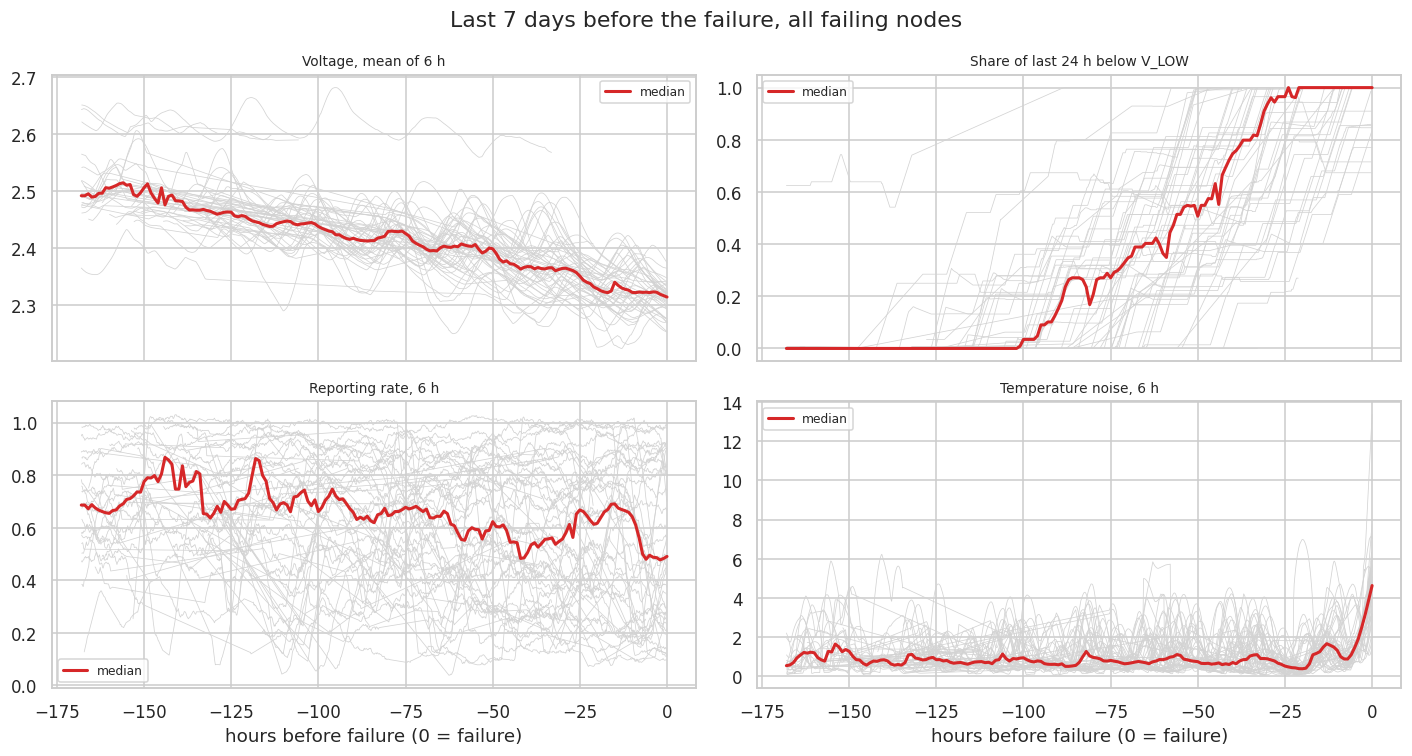

In [ ]:
d = data[data.ttf_h <= 7 * 24]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, (c, title) in zip(axes.ravel(), [("volt_mean_6h", "Voltage, mean of 6 h"), ("volt_low_share_24h", "Share of last 24 h below V_LOW"),
                                         ("report_rate_6h", "Reporting rate, 6 h"), ("temp_std_6h", "Temperature noise, 6 h")]):
    for m, g in d.groupby("moteid"):
        ax.plot(-g.ttf_h, g[c], color="lightgray", lw=0.5)
    med = d.groupby(d.ttf_h.round())[c].median()
    ax.plot(-med.index, med.values, color="tab:red", lw=2, label="median")
    ax.set_title(title, fontsize=9); ax.legend(loc="best", fontsize=8)
for ax in axes[-1]: ax.set_xlabel("hours before failure (0 = failure)")
plt.suptitle("Last 7 days before the failure, all failing nodes")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_before_failure.png", bbox_inches="tight"); plt.show()

**Observation (to write):** which curves move before 0? How many hours before? Is the move the same for most nodes?
A curve that falls steadily for days is a strong precursor. Remember: the nodes share the same battery decline, so many curves look alike.

## 6. When do the nodes fail? (to plan the split)
Because the failures cluster in time, a random split by node would be too optimistic. In notebook 03 we use a **forward-in-time split**:
train on the early period (with the early failures), validate on the next days, and keep the **last period locked for the test**,
with an embargo of horizon + longest window (about 2 days + H) between the sets.

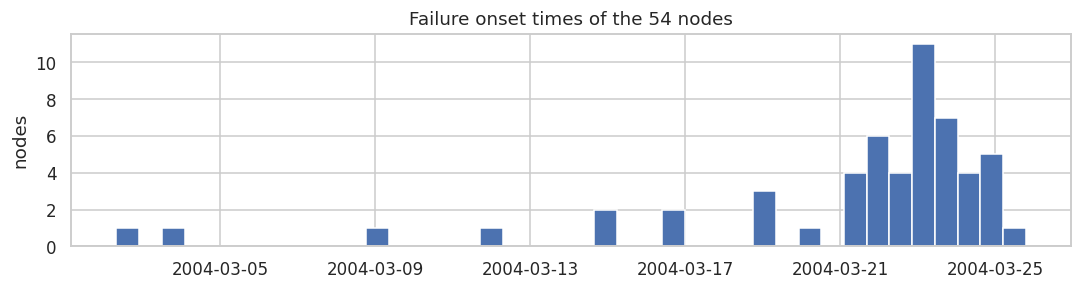

Failures per week:
t_onset
2004-03-01/2004-03-07     2
2004-03-08/2004-03-14     3
2004-03-15/2004-03-21    12
2004-03-22/2004-03-28    37
Freq: W-SUN

Failure onset quantiles:
0.100   2004-03-15 13:12:32.042016512
0.250   2004-03-21 06:28:24.963132288
0.500   2004-03-22 22:11:50.240257152
0.750   2004-03-23 20:18:35.518526080
0.900   2004-03-24 14:19:58.398284800


In [ ]:
fail = mote.dropna(subset=["t_onset"]).t_onset.sort_values()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.hist(fail, bins=40); ax.set_title("Failure onset times of the 54 nodes"); ax.set_ylabel("nodes")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_failure_times.png", bbox_inches="tight"); plt.show()
print("Failures per week:"); print(fail.dt.to_period("W").value_counts().sort_index().to_string())
print("\nFailure onset quantiles:"); print(fail.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).to_string())

## 7. Save for notebook 03

In [ ]:
out = data[FEATS + ["moteid", "ttf_h", "fail_type"]].copy()
out["fail_type"] = out["fail_type"].astype("category")
out.to_parquet(PROC_DIR / "features_intel.parquet")
mote[["fail_type", "first_ts", "last_ts", "t_onset", "t_lowv"]].to_csv(PROC_DIR / "mote_onsets.csv")

fmeta = {"grid": GRID, "windows_h": WINDOWS_H, "v_low": V_LOW, "n_features": len(FEATS), "features": FEATS,
         "rows": int(len(out)), "nodes": int(out.moteid.nunique()),
         "period": [str(out.index.min()), str(out.index.max())]}
(PROC_DIR / "features_intel_meta.json").write_text(json.dumps({k: v for k, v in fmeta.items() if k != "features"}, indent=2))
json.dump(FEATS, open(PROC_DIR / "feature_names_intel.json", "w"), indent=1)
print({k: v for k, v in fmeta.items() if k != "features"})

{'grid': '10min', 'windows_h': [1, 6, 24, 48], 'v_low': 2.4, 'n_features': 48, 'rows': 103177, 'nodes': 51, 'period': ['2004-03-01 01:20:00', '2004-03-25 18:40:00']}
